# Make terrain (and hydro?) spatial metrics from the Lidar HD MNT

## import libraries and other stuff, setup the workspace

In [1]:
import os
import sys

from matplotlib import colors

os.environ["PROJ_LIB"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["PROJ_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["GDAL_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/gdal"


import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rio
import pandas as pd

from rasterio.enums import Resampling

from pyproj import CRS

print(CRS.from_epsg(2154))

import rasterio
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge

EPSG:2154


In [2]:
# read some other data

gdf = gpd.read_file("../data/RNN_limite_poly_l93.shp")

gdf = gdf.set_crs("EPSG:2154")

In [31]:
# pour avoir gdf en raster :

gdf.to_file("/tmp/massane_boundary.gpkg", driver="GPKG")


import grass.script as gs
gs.run_command(
    "v.import",
    input="/tmp/massane_boundary.gpkg",
    output="massane_boundary",
    overwrite=True
)

In [3]:
bounds = gdf.total_bounds
west, south, east, north = bounds

print(west, south, east, north)

699836.8 6151842.4 703328.2 6155388.6


In [4]:
mnt_dir = Path("../../PhenoAnalysis/data/MNT_lidarHD")

full_mnt = mnt_dir / "mnt_mosaic.tif"

## config de GRASS

In [5]:
# 1. Configuration des chemins GRASS
grass_bin = "/usr/lib/grass83"
os.environ["GISBASE"] = grass_bin
sys.path.append(os.path.join(grass_bin, "etc", "python"))

# 2. Importer la bibliothèque de scripts GRASS
import grass.script as gs

grassdata = Path("grassdata").resolve()

In [7]:
# initialiser une session n'importe où la premier fois (pour pouvoir en creer une autre avec gs)
# import grass.jupyter as gj
# import grass.script as gs
#
# gj.init(grassdata, "project_massane_MNS", "PERMANENT")
#
#
#
# print("Création de la location 'project_massane_MNT'...")
# gs.create_location(
#     dbase=str(grassdata),
#     location="project_massane_MNT",
#     epsg=2154
# )

In [11]:
# 6. Démarrage de votre vraie session de travail sur le projet tout juste créé
from grass.script import setup as gsetup
import grass.jupyter as gj
# Start GRASS Session
session = gj.init(grassdata, "project_massane_MNT", "PERMANENT")

print("Session GRASS GIS initialisée sur project_massane_MNT [EPSG:2154].")

Session GRASS GIS initialisée sur project_massane_MNT [EPSG:2154].


## GRASS prétraitement

In [17]:
# importer le MNT natif

gs.run_command(
    "r.import",
    input=str(full_mnt),
    output="mnt_mosaic"
)

In [13]:
# # Set computational region to the elevation raster.
# gs.run_command("g.region",
#                raster="mnt_mosaic")

In [18]:
# set the region to the extent of the massane
gs.run_command(
        "g.region",
        w=west,
        s=south,
        e=east,
        n=north
    )

In [24]:
# degrader à 2m

# set the region to the extent of the massane
gs.run_command(
    "g.region",
    w=west,
    s=south,
    e=east,
    n=north,
    res = 2
)

# gs.run_command(
#     "g.region",
#     raster="mnt_mosaic",
#     res=2
# )

gs.run_command(
    "r.resamp.stats",
    input="mnt_mosaic",
    output="mnt_2m",
    method="average",
    overwrite = True
)

In [25]:
print(gs.parse_command("g.region", flags="p"))

{'projection: 99 (RGF93 v1 / Lambert-93)': None, 'zone:       0': None, 'datum:      towgs84': '0,0,0,0,0,0,0', 'ellipsoid:  grs80': None, 'north:      6155388.6': None, 'south:      6151842.4': None, 'west:       699836.8': None, 'east:       703328.2': None, 'nsres:      2.0001128': None, 'ewres:      1.99965636': None, 'rows:       1773': None, 'cols:       1746': None, 'cells:      3095658': None}


In [26]:
gs.run_command("r.slope.aspect",
                elevation="mnt_2m",
                slope="slope",
                aspect="aspect",
                flags="n")

In [36]:
#relief (better plots)
gs.run_command("r.relief",input="mnt_2m", output="relief", zscale=3)

## GRASS topo

In [27]:
# geo morpho class
gs.run_command("r.geomorphon",
                elevation="mnt_2m",
                forms="landforms200",
                search=200,
                skip=10,
                flat=1,
                comparison="anglev2_distance")

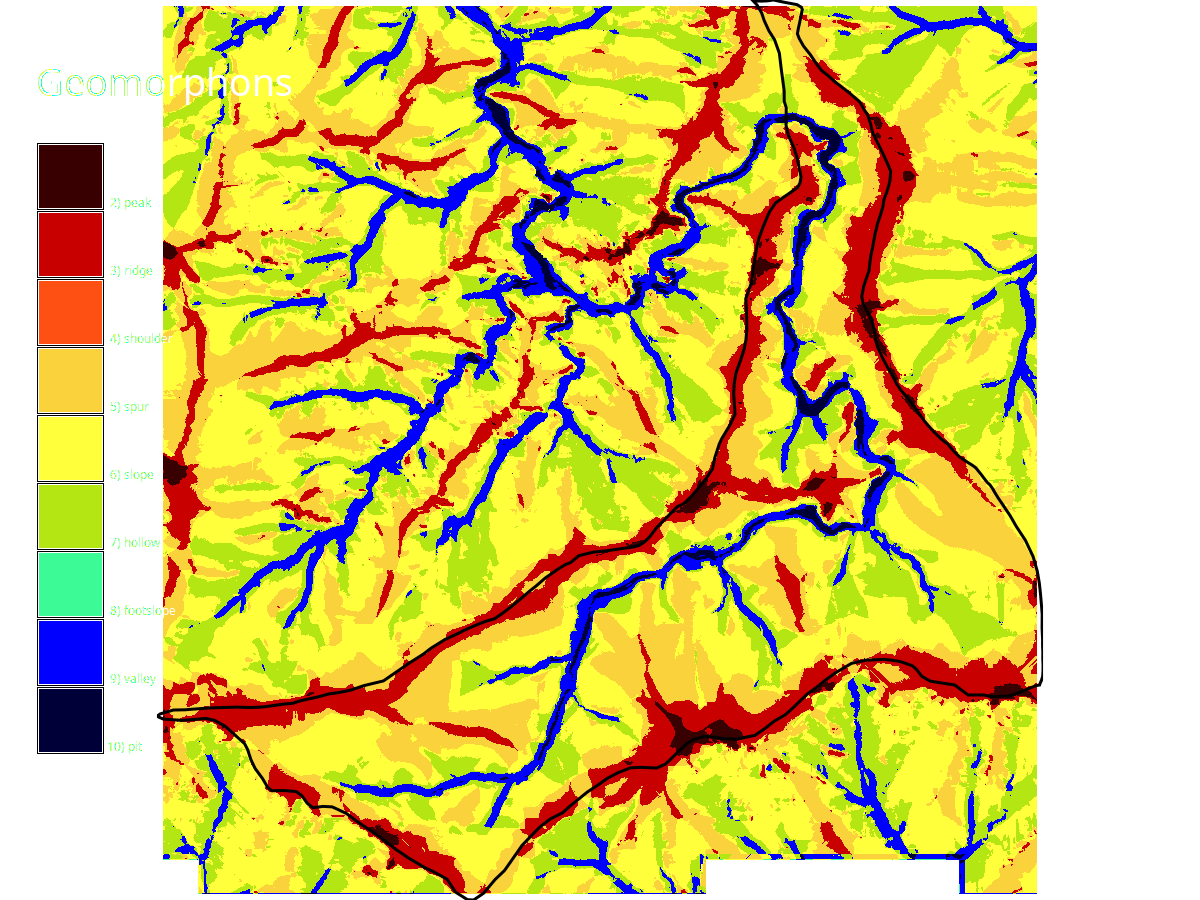

In [34]:
landform_map = gj.Map(width=1200, height=900)

landform_map.d_rast(
    map="landforms200"
)

landform_map.d_vect(
    map="massane_boundary",
    color="black",
    width=3,
    fill = "none"
)

landform_map.d_legend(
    raster="landforms200",
    title="Geomorphons",
    fontsize=12,
    color="white"
)


landform_map.show()

## hydro

In [70]:
gs.run_command("r.watershed",
                elevation="mnt_2m",
                threshold=20000,
                accumulation="watershed_accumulation",
                basin="watershed_basin",
                stream="watershed_streams",
                flags="ab")

In [71]:
gs.run_command("r.shade",
                shade="relief",
                color="watershed_basin",
                output="bassin_colored_relief",
                brighten=20)

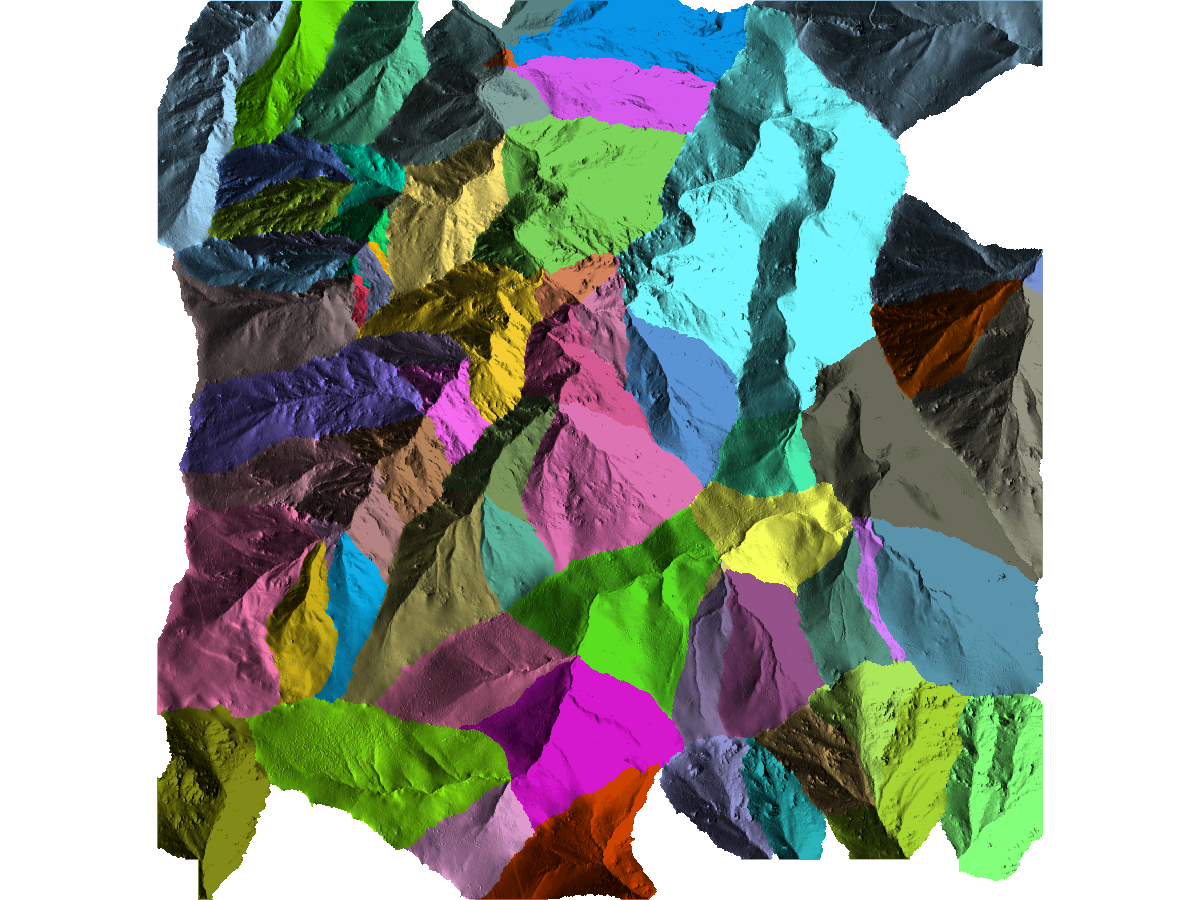

In [72]:
bassin_colored_relief_map = gj.Map(width=1200, height=900)

bassin_colored_relief_map.d_rast(
    map="bassin_colored_relief",
)

bassin_colored_relief_map.show()

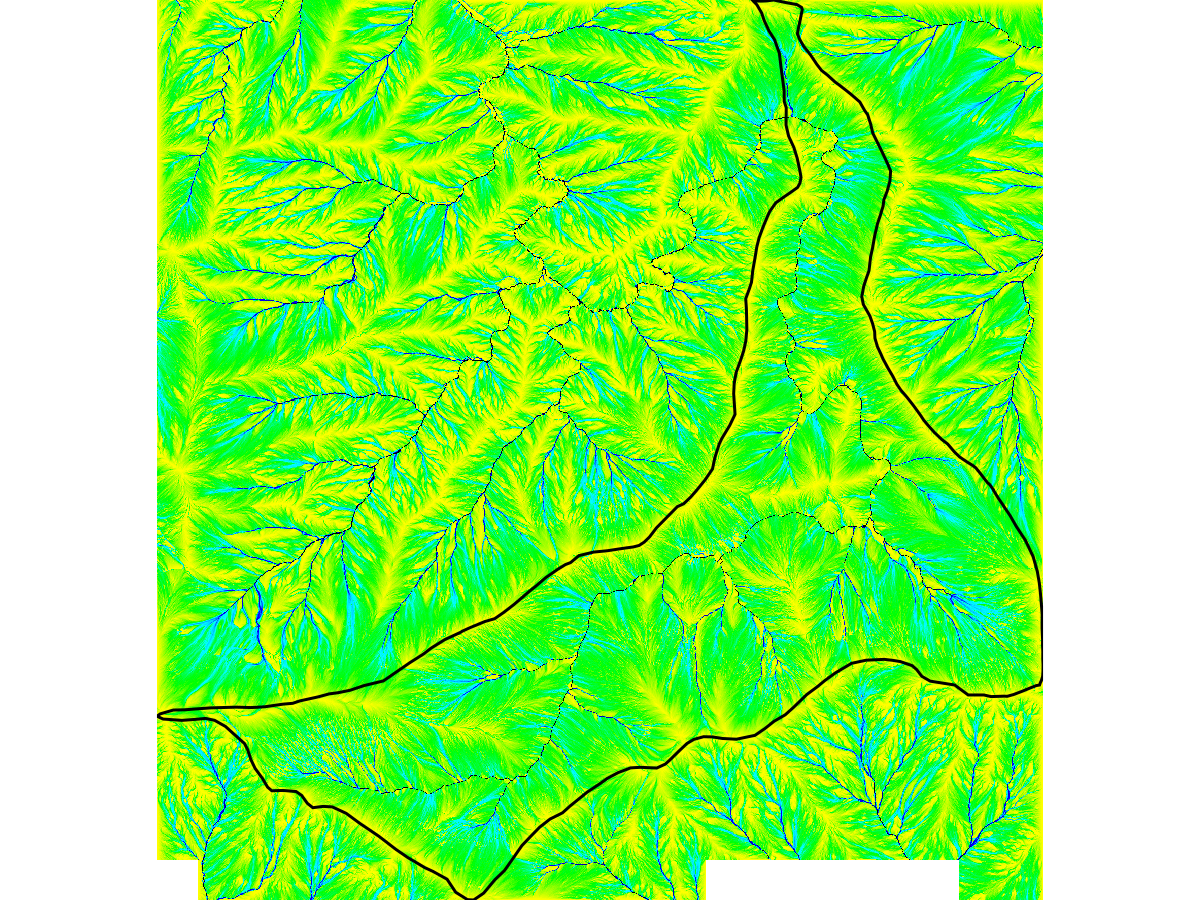

In [73]:
watershed_ac = gj.Map(width=1200, height=900)

watershed_ac.d_rast(
    map="watershed_accumulation",
)

watershed_ac.d_vect(
    map="massane_boundary",
    color="black",
    width=3,
    fill = "none"
)

watershed_ac.show()

## exporter ... au format xarray

In [5]:
# radiations globales

import xarray as xr
import rioxarray
from pathlib import Path

data_dir = Path("/home/abernard/PHOSFORH/PhenoAnalysis/Spatial_Metrics") # à changer

rasters = []

for doy in range(1, 366):

    path = data_dir / f"rad_{doy:03d}.tif"

    da = rioxarray.open_rasterio(path).squeeze("band", drop=True)
    da = da.expand_dims(DOY=[doy])

    rasters.append(da)

# Assemblage
rad_annual = xr.concat(rasters, dim="DOY")

# Nom de la variable
rad_annual.name = "global_radiation"

# CRS
rad_annual = rad_annual.rio.write_crs(rasters[0].rio.crs)

print(rad_annual)
print("CRS :", rad_annual.rio.crs)

<xarray.DataArray 'global_radiation' (DOY: 365, y: 1773, x: 1746)> Size: 5GB
array([[[ 513.4286 ,  530.2561 ,  533.4568 , ..., 3189.052  ,
         3417.6057 , 2806.1587 ],
        [ 497.57956,  512.92694,  518.2744 , ..., 3520.6804 ,
         3847.1938 , 2446.6543 ],
        [ 523.60675,  512.56647,  503.81876, ..., 3591.436  ,
         4100.6616 , 1969.7869 ],
        ...,
        [       nan,        nan,        nan, ..., 3269.4868 ,
         2980.7288 , 3840.8462 ],
        [       nan,        nan,        nan, ..., 3107.295  ,
         3684.228  , 3273.9426 ],
        [       nan,        nan,        nan, ..., 3524.2417 ,
         3613.8684 , 2275.4944 ]],

       [[ 515.0829 ,  531.96466,  535.17566, ..., 3197.7778 ,
         3427.6958 , 2815.8652 ],
        [ 499.18283,  514.57965,  519.94434, ..., 3527.819  ,
         3857.679  , 2456.9746 ],
        [ 525.2939 ,  514.218  ,  505.44214, ..., 3598.0222 ,
         4110.217  , 1978.6715 ],
...
        [       nan,        nan,        

In [15]:
# monter un netCDF
rad_annual.to_netcdf(
    data_dir / "global_radiation_massane_MNS_365days_2mres_v2.nc",
    encoding={
        "global_radiation": {
            "zlib": True,
            "complevel": 4
        }
    }
)

In [12]:
test = xr.open_dataset(data_dir / "global_radiation_massane_MNS_365days_2mres_v2.nc")

print(test)
print(test["global_radiation"].shape)

<xarray.Dataset> Size: 5GB
Dimensions:           (DOY: 365, y: 1773, x: 1746)
Coordinates:
  * DOY               (DOY) int64 3kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
  * y                 (y) float64 14kB 6.155e+06 6.155e+06 ... 6.152e+06
  * x                 (x) float64 14kB 6.998e+05 6.998e+05 ... 7.033e+05
Data variables:
    spatial_ref       int64 8B ...
    global_radiation  (DOY, y, x) float32 5GB ...
(365, 1773, 1746)
